# 02_data：資料：時間點檢查與品質報告

設定與協定見 `setup.yaml`；程式在 `src/s02_data.py`。預設 `RUN = False` 只讀已存的結果。

In [1]:
import os, sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT); sys.path.insert(0, str(ROOT))
import pandas as pd
from IPython.display import Image, Markdown, display
pd.set_option("display.max_columns", 40); pd.set_option("display.width", 200)
R = ROOT / "results"
def show(name, n=60):
    p = R / f"{name}.csv"
    display(Markdown(f"**{name}**")); display(pd.read_csv(p, encoding="utf-8-sig").head(n)) if p.exists() else print("缺", name)
def fig(name, w=800):
    p = R / "figures" / name
    display(Image(filename=str(p), width=w)) if p.exists() else print("缺圖", name)

In [2]:
RUN = False
if RUN:
    from src import s02_data
    s02_data.main()

**02_summary**

,Unnamed: 0,值
0,價格期間（檔案）,2005-01-03 ~ 2026-11-05
1,開發階段讀取至,2024-10-31
2,股票數（含下市）,2248
3,下市股（有價格）,269
4,下市股曾進入可投資池,224
5,下市名單中無價格,0
6,代號重複使用,0
7,"(日期, 代號) 重複（刪除）",0
8,殘缺日（整日刪除）,41
9,超過漲跌幅的跳動（抹平）,12012


**02_pit_checklist**

,層次,檢查項目,結果,證據
0,數值,特徵只用 t 日收盤以前的價量,PASS,s03 截斷重算：資料截在較早日期重算，重疊日期的特徵完全相同
1,數值,非價格資料的公布延遲,NaN,只用價量；除權息在除權息日前公告，還原為等比例係數
2,數值,還原價不引入未來資訊,PASS,視窗內價格比值只受視窗內的除權息影響；篩選用未還原價
3,數值,yfinance 的 Close 已還原分割,揭露,未還原價篩選（>= 10 元）對日後分割的股票偏低；台股分割少見
4,股票池,可投資條件只用 t 日資訊,PASS,"未還原收盤 >= 10、20 日均成交額 >= 2,000 萬、上市櫃滿 120 日、t 日有成交"
5,股票池,包含後來下市的股票,PASS,FinMind 補入 269 檔下市股
6,股票池,下市名單本身的完整性,FAIL→揭露,FinMind 名單無法與官方逐年核對；漏掉的下市股會讓結果偏樂觀
7,代號,代號重複使用,PASS,下市代號與現存代號重複 0 檔；重複者以「代號_d年份」分開，各自只用生效期間
8,代號,股票種類變更（ETF、TDR、特別股）,PASS,只取 4 碼普通股，排除 00xx、91xx、名稱含 DR
9,代號,更名,NaN,以代號為主鍵，名稱不參與計算


**02_coverage**

,年,現存股,後來下市,下市股占比
0,2005,203,46,0.184739
1,2006,289,69,0.192737
2,2007,385,74,0.161220
3,2008,322,50,0.134409
4,2009,486,63,0.114754
5,2010,579,70,0.107858
6,2011,502,58,0.103571
7,2012,345,47,0.119898
8,2013,484,55,0.102041
9,2014,603,64,0.095952


... (2 outputs left out)

**02_ohlc**

,來源,原始筆數,成交量為 0（刪除）,OHLC <= 0 或缺值（刪除）,"high < max(open, close)","low > min(open, close)"
0,yfinance,7797515,278582,2879,4959,3929
1,finmind,556987,12386,2348,4081,4031


**02_missing**

,年,存續格數,缺 K 棒格數,缺值比例
0,2005,188241,2959,0.015719
1,2006,191329,3218,0.016819
2,2007,189333,7352,0.038831
3,2008,330431,22868,0.069207
4,2009,331084,22235,0.067158
5,2010,339280,17063,0.050292
6,2011,345883,16251,0.046984
7,2012,359315,18698,0.052038
8,2013,383461,12838,0.033479
9,2014,402584,9497,0.023590


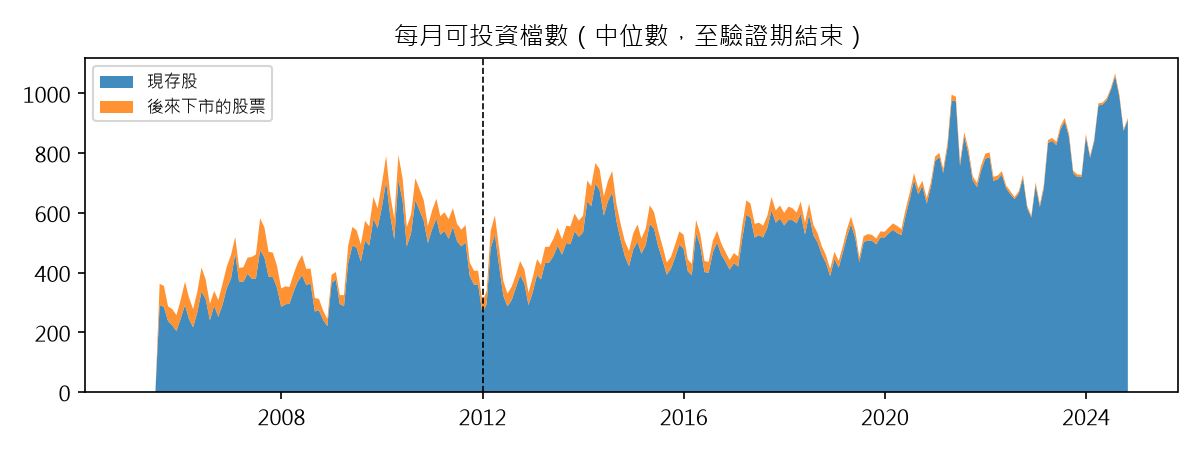

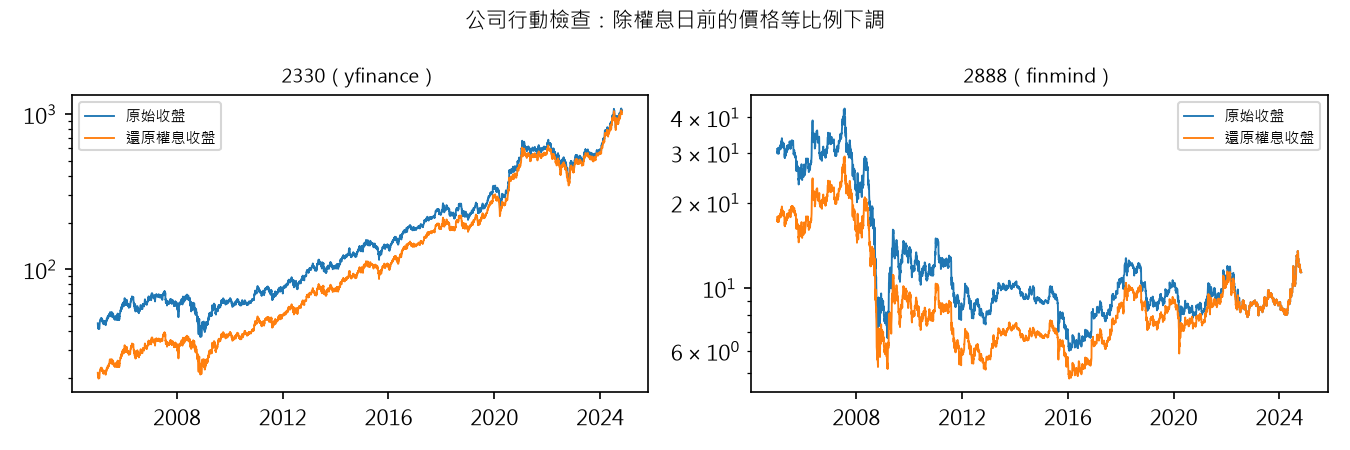

In [3]:
show("02_summary"); show("02_pit_checklist"); show("02_coverage"); show("02_survivorship"); show("02_ohlc"); show("02_missing")
fig("02_coverage.png"); fig("02_corporate_action.png")